# Adam Optimizer with Momentum for SMS Spam Classification

This notebook implements Logistic Regression using the Adam optimizer with momentum to classify SMS messages as Ham or Spam. The model will be trained and evaluated using the same dataset and preprocessing steps used in the previous notebooks.

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import warnings
warnings.filterwarnings('ignore')

# Dataset Loading¶
In this section, we locate the dataset files available in the Kaggle environment. This step helps us identify the file path before loading the SMS Spam Collection dataset into our project.

In [96]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.lower().endswith('.csv'):
            print(os.path.join(dirname, filename))

/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv


# Loading the Dataset
In this step, we load the SMS Spam Collection dataset using Pandas. The dataset contains SMS messages labeled as either spam or ham. We will use these messages to build our binary classification model.

In [97]:
df = pd.read_csv("/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv", encoding="latin-1")

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


# Data Exploration
In this section, we will explore the dataset structure, column names, and missing values to understand the data before preprocessing.



In [98]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (5572, 5)

Column Names:
Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB

Missing Values:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64


# Data Cleaning and Preprocessing
In this section, we will remove unnecessary columns, keep the SMS labels and message text, and convert the labels into numerical values for Logistic Regression.

In [99]:
# Keep only the required columns
df = df[['v1', 'v2']].copy()

# Rename columns
df.columns = ['label', 'message']

# Convert labels into numerical values
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

# Display the cleaned dataset
print(df.head())

print("\nClass Distribution:")
print(df['label'].value_counts())

   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...

Class Distribution:
label
0    4825
1     747
Name: count, dtype: int64


# Train-Test Split
In this section, we will split the dataset into training and testing sets. We will use 80% of the data for training and 20% for testing while maintaining the same class distribution.

In [100]:
X = df['message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4457
Testing samples: 1115


# Text Vectorization using TF-IDF
In this section, we will convert SMS messages into numerical features using TF-IDF. This allows the Logistic Regression model to process text data. We will fit the vectorizer on the training data and apply it to the testing data.

In [101]:
tfidf = TfidfVectorizer(max_features=3000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Logistic Regression Model¶
In this section, we will implement Logistic Regression from scratch. We will define the Sigmoid function to calculate probabilities and the Binary Cross-Entropy Loss to measure prediction errors. These functions will be used by all five optimization algorithms.

In [102]:
# Sigmoid Function
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# Binary Cross-Entropy Loss
def compute_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss


# Calculate Gradients
def compute_gradients(X, y, weights, bias):
    n = X.shape[0]

    predictions = sigmoid(X @ weights + bias)
    errors = predictions - y

    dw = np.asarray(X.T @ errors).ravel() / n
    db = np.mean(errors)

    return dw, db

# Adam Optimizer with Momentum

In this section, we implement the Adam optimizer for Logistic Regression. Adam combines momentum and adaptive learning rates by using the first and second moments of the gradients to update the model parameters efficiently.

In [103]:
def train_adam(X, y, learning_rate=0.01,
               beta1=0.9, beta2=0.999,
               epochs=100, epsilon=1e-8):

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    m_w = np.zeros(n_features)
    m_b = 0.0

    v_w = np.zeros(n_features)
    v_b = 0.0

    losses = []

    for epoch in range(1, epochs + 1):

        dw, db = compute_gradients(X, y, weights, bias)

        # First moment estimate
        m_w = beta1 * m_w + (1 - beta1) * dw
        m_b = beta1 * m_b + (1 - beta1) * db

        # Second moment estimate
        v_w = beta2 * v_w + (1 - beta2) * (dw ** 2)
        v_b = beta2 * v_b + (1 - beta2) * (db ** 2)

        # Bias correction
        m_w_corrected = m_w / (1 - beta1 ** epoch)
        m_b_corrected = m_b / (1 - beta1 ** epoch)

        v_w_corrected = v_w / (1 - beta2 ** epoch)
        v_b_corrected = v_b / (1 - beta2 ** epoch)

        # Update parameters
        weights -= learning_rate * m_w_corrected / (
            np.sqrt(v_w_corrected) + epsilon
        )

        bias -= learning_rate * m_b_corrected / (
            np.sqrt(v_b_corrected) + epsilon
        )

        predictions = sigmoid(X @ weights + bias)
        loss = compute_loss(y, predictions)
        losses.append(loss)

    return weights, bias, losses

# Model Training

In this section, we train the Logistic Regression model using the Adam optimizer with momentum. We use the training dataset and define the learning rate, beta parameters, and number of epochs.

In [104]:
weights_adam, bias_adam, losses_adam = train_adam(
    X_train_tfidf,
    y_train.to_numpy(),
    learning_rate=0.01,
    beta1=0.9,
    beta2=0.999,
    epochs=100,
    epsilon=1e-8
)

print("Final Training Loss:", losses_adam[-1])

Final Training Loss: 0.1451837305309466


## Model Evaluation

In this section, we evaluate the trained Adam model using the test dataset. We calculate Accuracy, Precision, Recall, F1 Score, and Binary Cross-Entropy Loss to measure the model's classification performance.

In [105]:
y_test_array = y_test.to_numpy()

y_prob_adam = sigmoid(X_test_tfidf @ weights_adam + bias_adam)
y_pred_adam = (y_prob_adam >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test_array, y_pred_adam))
print("Precision:", precision_score(y_test_array, y_pred_adam, zero_division=0))
print("Recall:", recall_score(y_test_array, y_pred_adam, zero_division=0))
print("F1 Score:", f1_score(y_test_array, y_pred_adam, zero_division=0))
print("Test Loss:", compute_loss(y_test_array, y_prob_adam))

Accuracy: 0.9704035874439462
Precision: 0.9754098360655737
Recall: 0.7986577181208053
F1 Score: 0.8782287822878229
Test Loss: 0.16955456607601588


# Confusion Matrix

In this section, we visualize the confusion matrix to examine how well the Adam model classifies Ham and Spam messages and identify correct and incorrect predictions.

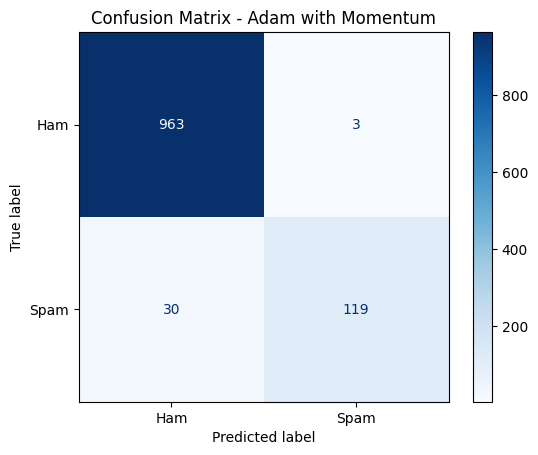

[[963   3]
 [ 30 119]]


In [106]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_adam = confusion_matrix(y_test_array, y_pred_adam)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_adam,
    display_labels=['Ham', 'Spam']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Adam with Momentum')
plt.show()

print(cm_adam)

# Evaluation Metrics Comparison

This bar chart compares the Adam model's Accuracy, Precision, Recall, and F1 Score to provide a visual overview of its classification performance.

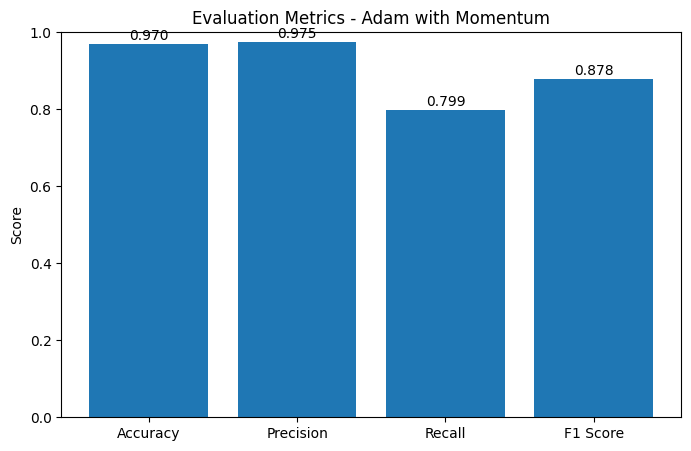

In [107]:
metrics = {
    'Accuracy': accuracy_score(y_test_array, y_pred_adam),
    'Precision': precision_score(y_test_array, y_pred_adam, zero_division=0),
    'Recall': recall_score(y_test_array, y_pred_adam, zero_division=0),
    'F1 Score': f1_score(y_test_array, y_pred_adam, zero_division=0)
}

plt.figure(figsize=(8, 5))
plt.bar(metrics.keys(), metrics.values())

plt.title('Evaluation Metrics - Adam with Momentum')
plt.ylabel('Score')
plt.ylim(0, 1)

for i, value in enumerate(metrics.values()):
    plt.text(i, value + 0.01, f'{value:.3f}', ha='center')

plt.show()

# Training Loss Curve

This plot shows how the Binary Cross-Entropy Loss changes during training across 100 epochs. It helps us understand how the Adam optimizer learns and whether the training process converges.

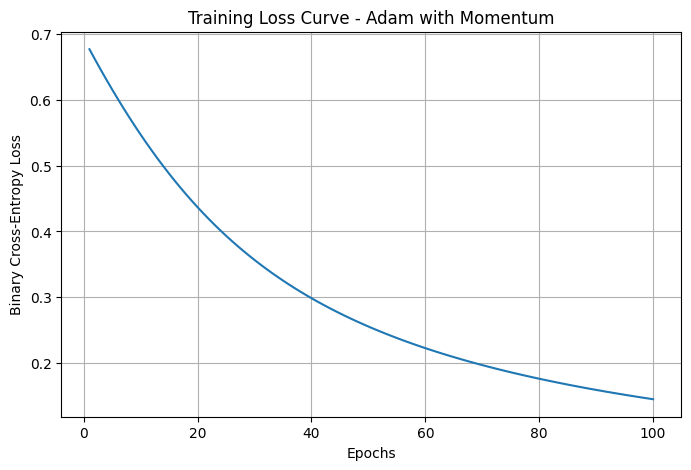

In [108]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, len(losses_adam) + 1), losses_adam)

plt.title('Training Loss Curve - Adam with Momentum')
plt.xlabel('Epochs')
plt.ylabel('Binary Cross-Entropy Loss')
plt.grid(True)

plt.show()

# Actual vs Predicted Distribution

In this section, we compare the actual and predicted number of Ham and Spam messages to observe how closely the model's predictions match the actual class distribution.

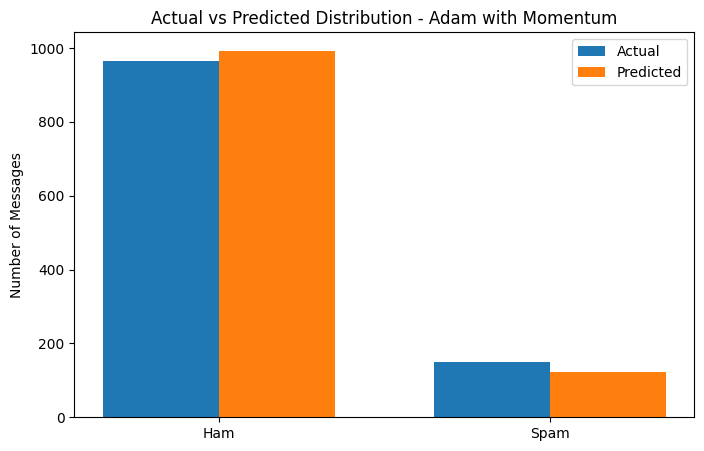

Actual Counts: [np.int64(966), np.int64(149)]
Predicted Counts: [np.int64(993), np.int64(122)]


In [109]:
actual_counts = pd.Series(y_test_array).value_counts().sort_index()
predicted_counts = pd.Series(y_pred_adam).value_counts().sort_index()

labels = ['Ham', 'Spam']
actual = [actual_counts.get(0, 0), actual_counts.get(1, 0)]
predicted = [predicted_counts.get(0, 0), predicted_counts.get(1, 0)]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, actual, width, label='Actual')
plt.bar(x + width/2, predicted, width, label='Predicted')

plt.xticks(x, labels)
plt.ylabel('Number of Messages')
plt.title('Actual vs Predicted Distribution - Adam with Momentum')
plt.legend()

plt.show()

print("Actual Counts:", actual)
print("Predicted Counts:", predicted)

# Results Summary Table

In this section, we summarize the Adam optimizer settings and its evaluation results. The table provides an overview of the training configuration and the model's performance on the test dataset.

In [110]:
results = {
    'Parameter': [
        'Optimizer',
        'Learning Rate',
        'Beta1',
        'Beta2',
        'Epochs',
        'Training Loss',
        'Test Loss',
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score'
    ],
    'Value': [
        'Adam with Momentum',
        0.01,
        0.9,
        0.999,
        100,
        losses_adam[-1],
        compute_loss(y_test_array, y_prob_adam),
        accuracy_score(y_test_array, y_pred_adam),
        precision_score(y_test_array, y_pred_adam, zero_division=0),
        recall_score(y_test_array, y_pred_adam, zero_division=0),
        f1_score(y_test_array, y_pred_adam, zero_division=0)
    ]
}

pd.DataFrame(results)

,Parameter,Value
0,Optimizer,Adam with Momentum
1,Learning Rate,0.01
2,Beta1,0.9
3,Beta2,0.999
4,Epochs,100
5,Training Loss,0.145184
6,Test Loss,0.169555
7,Accuracy,0.970404
8,Precision,0.97541
9,Recall,0.798658
